# C02h — Adaptive control against human prefix trajectories
Regenerate the eight original C02e2 texts with the same ordinary greedy baseline and a moving-reference controller. **No edit, intervention, search-count, depth, or output-length budgets.** Natural EOS ends generation; context/OOM/interruption is incomplete and resumable.

At generated alphabetic-word count w, compare k=V/w with the Q20, Q40, Q50 and Q60 of **human prefixes at exactly w words**. The original text length selects the same 30 nearest training humans within domain (pooled fallback if fewer than 15 domain humans). Each reference contributes only while it has at least w words. References are never padded, extrapolated, or replaced as generation advances. At least 15 available references are required; beyond that support, ordinary decoding continues with an explicit unsupported status in the trajectory. Reference coverage is reported alongside outcomes. Long-prefix quantiles therefore describe the surviving longer passages, not an unchanged cohort.

The first ceil(0.15 × original word count) generated words are ordinary. After warm-up, enter decrease above moving Q60, or increase below moving Q20. Stay active until crossing moving Q40. Higher unique-word share is treated as the AI-like direction for this experiment. Missing support resets control; resumption uses current boundaries.

For an active mode, Q is distance from Q40 toward the active side divided by that side's Q40-to-outer-boundary width, floored at 1/w. Use:

θ(Q) = θ_min + (θ_max − θ_min) / (1 + exp(slope × (Q − midpoint))).

**Larger deviation lowers θ and admits more alternatives.** Separate schedules are configurable for increase/decrease. Defaults are exploratory, not fitted: min=.005, max=.10, slope=4, midpoint=1. At Q=1, θ=.0525. There is no guarantee of target tracking or meaning preservation.

Tentatively generate a complete word, and backtrack only if its novelty conflicts with control. Search best-first over alternate token paths. Word-forming tokens must meet raw conditional probability θ (no renormalization/top-k). **Boundary exception:** if the ordinary greedy next token merely confirms an already-spelled word, it may be used below θ. It must leave that word's characters unchanged. This uses ordinary greedy confirmation, not exhaustive enumeration of every possible low-probability delimiter. A token that adds letters to the current word still requires θ. All exemptions and candidate paths are logged.

Report fraction in band, mean/max departure, normalized departure, longest excursion, endpoint membership, and reference coverage after warm-up. Marginal-band tracking is not a guarantee of matching human temporal structure. Full-model context recomputation prioritizes correctness over speed.

In [1]:
IMPLEMENTATION_SHA256 = '20be1dd3762f6344459d7fdd4dfdf0db5e3001dcb283074399fb7cb5038542af'
from pathlib import Path
import json, hashlib, math, os, time, uuid, html, inspect
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path('..')
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT / 'results/causal/C02e2_raid_feature_guided'
OUT = ROOT / 'results/causal/C02h_adaptive_prefix_control'
MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
MODEL_REVISION = 'main'  # resolved commit is recorded; pin it when reproducing elsewhere
WARMUP_FRACTION = 0.15
MIN_PREFIX_SUPPORT = 15
THETA_SCHEDULES = {
    'increase': dict(minimum=.005, maximum=.10, slope=4., midpoint=1.),
    'decrease': dict(minimum=.005, maximum=.10, slope=4., midpoint=1.),
}
for schedule in THETA_SCHEDULES.values():
    assert 0 < schedule['minimum'] <= schedule['maximum'] <= 1
    assert schedule['slope'] > 0
OUT.mkdir(parents=True, exist_ok=True)

def digest(x):
    return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False,allow_nan=False).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False))
    os.replace(tmp,path)

## Dependencies and exact word accounting
Run in the existing research environment. If needed: `%pip install torch transformers spacy pandas numpy matplotlib pyarrow` and `!python -m spacy download en_core_web_sm`. The full detector extractor is unnecessary for the decoding experiment. The tokenizer uses the same spaCy alphabetic-token definition, checked against cached original and reference features below.

In [2]:
# Human prefix references and adaptive control helpers.
import math

def prefix_curve(word_lists, minimum_support=15):
    """Empirical quantiles at absolute alphabetic-word position; no extrapolation."""
    import numpy as np
    trajectories=[]
    for words in word_lists:
        seen=set(); trajectory=[]
        for w,word in enumerate(words,1):
            seen.add(word.lower()); trajectory.append(len(seen)/w)
        trajectories.append(trajectory)
    curve={}
    for w in range(1,max(map(len,trajectories),default=0)+1):
        ratios=[t[w-1] for t in trajectories if len(t)>=w]
        n=len(ratios)
        entry=dict(W=w,reference_n=n,supported=n>=minimum_support)
        if entry['supported']:
            entry.update(zip(['H_h30','H_h10','H_median','H_a10'],
                map(float,np.quantile(ratios,[.2,.4,.5,.6],method='linear'))))
        curve[str(w)]=entry
    return curve

def reference_at(curve,w):
    return curve.get(str(w),dict(W=w,reference_n=0,supported=False))

def adaptive_mode(previous,V,W,warmup_words,ref):
    if W<warmup_words or W==0: return 'normal'
    if not ref['supported']: return 'unsupported'
    k=V/W
    if previous=='increase' and k<ref['H_h10']: return 'increase'
    if previous=='decrease' and k>ref['H_h10']: return 'decrease'
    if k<ref['H_h30']: return 'increase'
    if k>ref['H_a10']: return 'decrease'
    return 'normal'

def adaptive_theta(mode,k,w,ref,schedules):
    if mode not in ('increase','decrease'): return None,None
    width=(ref['H_a10']-ref['H_h10'] if mode=='decrease'
           else ref['H_h10']-ref['H_h30'])
    q=max(0.,(k-ref['H_h10'] if mode=='decrease' else ref['H_h10']-k)/max(width,1/w))
    s=schedules[mode]
    assert 0<s['minimum']<=s['maximum']<=1 and s['slope']>0
    z=s['slope']*(q-s['midpoint'])
    sigmoid=math.exp(-z)/(1+math.exp(-z)) if z>=0 else 1/(1+math.exp(z))
    return float(s['minimum']+(s['maximum']-s['minimum'])*sigmoid),float(q)

def trajectory_metrics(trajectory,warmup_words):
    # Include word warmup+1 onward: these are the words eligible for intervention.
    eligible=[t for t in trajectory if t['W_after']>warmup_words]
    supported=[t for t in eligible if t['reference_after']['supported']]
    distances=[]; normalized=[]; longest=run=0
    for t in eligible:
        r=t['reference_after']
        if not r['supported']:
            run=0;continue
        k=t['k_after']; d=max(r['H_h30']-k,0.,k-r['H_a10'])
        distances.append(d)
        normalized.append(d/max(r['H_a10']-r['H_h30'],1/t['W_after']))
        run=run+1 if d>0 else 0;longest=max(longest,run)
    n=len(supported)
    return dict(post_warmup_words=len(eligible),supported_words=n,
        unsupported_words=len(eligible)-n,
        reference_coverage=n/len(eligible) if eligible else None,
        fraction_in_band=sum(d==0 for d in distances)/n if n else None,
        mean_band_distance=sum(distances)/n if n else None,
        mean_normalized_band_distance=sum(normalized)/n if n else None,
        maximum_band_distance=max(distances) if n else None,
        longest_outside_run=longest if n else None)

import torch
import spacy
from transformers import AutoTokenizer, AutoModelForCausalLM
nlp = spacy.load('en_core_web_sm')

def word_spans(text):
    # C02e2 normalizes newlines to spaces before feature extraction; preserve offsets.
    normalized = text.translate(str.maketrans({'\n':' ', '\r':' '}))
    return [(t.text,t.idx,t.idx+len(t.text)) for t in nlp.make_doc(normalized) if t.is_alpha]

def counts(text):
    words = [w.lower() for w,_,_ in word_spans(text)]
    return len(set(words)),len(words)

features = pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus = pd.read_parquet(BASE/'paired_corpus.parquet')
selection = pd.read_csv(PRIOR/'raid_micro_selection.csv')
assert len(selection)==8 and selection.source_id.is_unique
assert features.source_id.is_unique and corpus.source_id.is_unique
humans = features.loc[(features.dataset=='raid') & (features.split=='train') & (features.label==0)].copy()
assert len(humans)>=30
text_map=corpus.set_index('source_id').text.to_dict()
feature_map=features.set_index('source_id')
cases=[]; references=[]
for row in selection.to_dict('records'):
    original=str(text_map[row['source_id']]); V,W=counts(original)
    assert W>0
    cached=feature_map.loc[row['source_id']]
    assert np.isclose(V/W,float(cached.share_unique_words),atol=1e-10,rtol=0)
    pool=humans.loc[humans.domain==row['domain']].copy()
    fallback=len(pool)<15
    if fallback: pool=humans.copy()
    pool['length_distance']=abs(np.log(pool.n_words.clip(lower=1))-np.log(W))
    neighbors=pool.sort_values(['length_distance','source_id']).head(30)
    for r in neighbors.itertuples():
        rv,rw=counts(str(text_map[r.source_id]))
        assert rw and np.isclose(rv/rw,float(r.share_unique_words),atol=1e-10,rtol=0)
        references.append(dict(case_id=row['case_id'],source_id=r.source_id,W=rw,ratio=rv/rw,
            words=[word.lower() for word,_,_ in word_spans(str(text_map[r.source_id]))]))
    human_curve=prefix_curve([r['words'] for r in references if r['case_id']==row['case_id']],MIN_PREFIX_SUPPORT)
    cases.append(dict(case_id=row['case_id'],source_id=row['source_id'],domain=row['domain'],
        original=original,V_ref=V,W_ref=W,original_ratio=V/W,
        warmup_words=math.ceil(W*WARMUP_FRACTION),curve=human_curve,
        reference_fallback=fallback,reference_n=len(neighbors)))
display(pd.DataFrame([{**{k:v for k,v in c.items() if k not in ('original','curve')},
    'last_supported_word':max((int(w) for w,r in c['curve'].items() if r['supported']),default=0)} for c in cases]))

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,case_id,source_id,domain,V_ref,W_ref,original_ratio,warmup_words,reference_fallback,reference_n,last_supported_word
0,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,recipes,129,249,0.518072,38,False,30,250
1,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,wiki,149,245,0.608163,37,False,30,236
2,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,reddit,79,107,0.738318,17,False,30,155
3,raid_micro_04,ai__raid:140bcdd4-cb85-49b7-ad40-483a21380193,news,189,343,0.551020,52,False,30,331
4,raid_micro_05,ai__raid:e9f78f95-8a2d-4a0a-a47a-044c9c6c5c22,reddit,93,158,0.588608,24,False,30,164
5,raid_micro_06,ai__raid:efc8537a-8575-4af0-aae5-a06bc4bccc04,books,137,270,0.507407,41,False,30,263
6,raid_micro_07,ai__raid:0f754d71-62ae-4f45-9e67-7c835bc8ebe1,poetry,172,238,0.722689,36,False,30,243
7,raid_micro_08,ai__raid:3bc610dd-010e-480c-8af3-1c5da8728644,abstracts,63,111,0.567568,17,False,30,120


## Adaptive controller engine
Word counts use the same lowercased alphabetic spaCy tokens as C02e2. Each committed word records its before/after human boundaries, support, Q, θ, action, and search diagnostics. Prefix text remains unchanged by backtracking, including model tokens that straddle word boundaries.

In [3]:
# Word feedback engine. Pure Python except for the supplied generator/tokenizer backend.
import math
import heapq
from collections import Counter

class IncompleteGeneration(RuntimeError):
    """Operational or boundary failure; never interpreted as exhausted alternatives."""


def first_closed_word(backend, ids, fixed_prefix):
    """Return first fully delimited alphabetic spaCy token after fixed_prefix.
    Wait for whitespace (or EOS) to stabilize tokenization of contractions and
    punctuation inside the current chunk. A model token may span several words.
    Only the first word is committed; later characters remain tentative.
    """
    text = backend.decode(tuple(ids))
    stable = text.rstrip('\ufffd')
    common = min(len(stable), len(fixed_prefix))
    if stable[:common] != fixed_prefix[:common]:
        return dict(kind='prefix_conflict', text=text)
    if len(stable) < len(fixed_prefix):
        if backend.ended(ids):
            return dict(kind='prefix_conflict', text=text)
        return dict(kind='pending', text=text)
    final = backend.ended(ids)
    if final:
        if '\ufffd' in text:
            raise IncompleteGeneration('EOS with undecodable byte sequence.')
        closed_end = len(text)
    else:
        closed_end = max((i+1 for i,c in enumerate(stable) if c.isspace()), default=0)
    if closed_end < len(fixed_prefix):
        return dict(kind='pending', text=text)
    for word, start, end in backend.word_spans(text[:closed_end]):
        if start < len(fixed_prefix) < end:
            raise IncompleteGeneration('Tokenizer changed a previously committed word boundary.')
        if start >= len(fixed_prefix):
            return dict(kind='word', word=word, start=start, end=end, text=text)
    return dict(kind='end' if final else 'pending', text=text)


def greedy_to_word(backend, ids, probabilities, fixed_prefix):
    ids, probabilities = list(ids), list(probabilities)
    while True:
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] in {'word', 'end'}:
            return dict(ids=ids, probabilities=probabilities, view=view)
        if view['kind'] == 'prefix_conflict':
            raise IncompleteGeneration('Ordinary decoding changed committed text.')
        choices = backend.choices(tuple(ids), threshold=None)
        if not choices:
            raise IncompleteGeneration('No permitted next token in ordinary decoding.')
        token, probability = choices[0]
        ids.append(int(token)); probabilities.append(float(probability))


def backtrack_anchor(backend, baseline_ids, fixed_prefix):
    # Find a token boundary at or before the character boundary. If a token
    # straddles an earlier committed word and the new word, replay that token
    # while constraining its already-committed characters exactly.
    for n in range(len(baseline_ids), -1, -1):
        prefix_ids = tuple(baseline_ids[:n])
        if backend.ended(prefix_ids):
            continue
        text = backend.decode(prefix_ids)
        if '\ufffd' not in text and fixed_prefix.startswith(text):
            return n
    raise IncompleteGeneration('No valid token checkpoint for this word.')


def search_word(backend, baseline, fixed_prefix, seen, desired, theta,
                on_search=lambda event: None):
    """Best-first search over paths whose word-forming tokens have raw
    probability >= theta. Greedy boundary-only confirmation is exempt. No search-count or depth cutoff.
    Completed undesired words terminate their branch. An operational failure
    propagates rather than masquerading as 'no alternative'.
    """
    if desired not in {'increase', 'decrease'} or not 0 < theta <= 1:
        raise ValueError('Invalid search mode or probability threshold.')
    anchor = backtrack_anchor(backend, baseline['ids'], fixed_prefix)
    root = tuple(baseline['ids'][:anchor])
    heap = [(0.0, 0, (), ())]
    serial = 0; expanded = 0; completed = 0; distinct=set()
    while heap:
        negative_logp, _, suffix, probs = heapq.heappop(heap)
        ids = root + suffix
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] == 'prefix_conflict':
            continue
        if view['kind'] == 'word':
            novel = view['word'].lower() not in seen
            acceptable = novel if desired == 'increase' else not novel
            completed += 1; distinct.add(view['word'].lower())
            on_search(dict(event='completed_candidate', word=view['word'], novel=novel,
                acceptable=acceptable, branch_log_probability=-negative_logp,
                branch_tokens=list(suffix), branch_probabilities=list(probs),
                expanded=expanded, frontier=len(heap)))
            if acceptable:
                return dict(ids=list(ids), probabilities=baseline['probabilities'][:anchor]+list(probs),
                    view=view, anchor=anchor, branch_tokens=list(suffix),
                    branch_probabilities=list(probs), expanded=expanded,
                    completed_candidates=completed, distinct_candidates=len(distinct), exhausted=False,
                    boundary_exempt_indices=[i for i,p in enumerate(probs) if p<theta])
            continue
        if view['kind'] == 'end':
            continue
        # Full distribution is filtered ONLY by the declared probability threshold
        # and the fixed exclusion of non-EOS protocol/control tokens.
        choices = backend.choices(ids, threshold=theta)
        # Boundary-only confirmation may follow the ordinary greedy token below
        # theta. It must close an already-spelled word without changing its letters.
        greedy = backend.choices(ids, threshold=None)
        exempt_token=None
        if greedy and greedy[0][1]<theta:
            token,p=greedy[0]
            before_text=backend.decode(ids)
            after_view=first_closed_word(backend, ids+(int(token),), fixed_prefix)
            boundary_only=(after_view['kind']=='word'
                and after_view['end']<=len(before_text)
                and before_text[:after_view['end']]==after_view['text'][:after_view['end']]
                and '\ufffd' not in before_text)
            if boundary_only:
                choices=choices+[(token,p)]; exempt_token=token
        on_search(dict(event='eligibility',theta=theta,
            eligible_lexical_or_boundary_tokens=len(choices)-int(exempt_token is not None),
            greedy_probability=greedy[0][1] if greedy else None,
            greedy_below_threshold=bool(greedy and greedy[0][1]<theta),
            boundary_exemption=exempt_token is not None))
        expanded += 1
        for token, probability in choices:
            assert probability >= theta or token==exempt_token
            serial += 1
            heapq.heappush(heap, (negative_logp-math.log(probability), serial,
                suffix+(int(token),), probs+(float(probability),)))
        on_search(dict(event='expanded', expanded=expanded, frontier=len(heap),
                       eligible_children=len(choices)))
    return dict(exhausted=True, expanded=expanded, completed_candidates=completed, distinct_candidates=len(distinct), anchor=anchor)


def initial_state(condition):
    return dict(condition=condition, ids=[], probabilities=[], committed_text='',
                words=[], mode='normal', trajectory=[], finished=False, status='ready',
                search_attempts=0, replacements=0, fallbacks=0)


def run_feedback(backend, state, curve, warmup_words, schedules,
                 checkpoint=lambda state: None, on_search=lambda event: None,
                 on_status=lambda state: None):
    # state is only mutated after a complete word is selected. During search it
    # stays at the last valid checkpoint; interruption cannot commit half a word.
    try:
        while not state['finished']:
            W = len(state['words']); seen = set(state['words']); V = len(seen)
            ref=reference_at(curve,W)
            mode=adaptive_mode(state['mode'],V,W,warmup_words,ref)
            if state['condition'] == 'baseline': mode = 'normal'
            theta,Q=adaptive_theta(mode,V/W if W else 0.,W,ref,schedules)
            ordinary = greedy_to_word(backend, state['ids'], state['probabilities'], state['committed_text'])
            if ordinary['view']['kind'] == 'end':
                state.update(ids=ordinary['ids'], probabilities=ordinary['probabilities'],
                    committed_text=ordinary['view']['text'], finished=True, status='completed_eos')
                actual = [w.lower() for w,_,_ in backend.word_spans(state['committed_text'])]
                if actual != state['words']:
                    state['finished'] = False
                    raise IncompleteGeneration('Final tokenizer counts differ from the committed-word ledger.')
                state.pop('last_error', None)
                checkpoint(state); on_status(state); break
            original_word = ordinary['view']['word']
            original_novel = original_word.lower() not in seen
            conflict = (mode == 'increase' and not original_novel) or (mode == 'decrease' and original_novel)
            selected = ordinary; action = 'ordinary'; info = {}
            if conflict:
                # Freeze all preceding text, including intervening punctuation.
                fixed_prefix = ordinary['view']['text'][:ordinary['view']['start']]
                info = search_word(backend, ordinary, fixed_prefix, seen, mode, theta, on_search)
                if info['exhausted']:
                    action = 'fallback_exhausted'
                else:
                    selected = info; action = 'backtracked'
            word = selected['view']['word']; novel = word.lower() not in seen
            if action == 'backtracked':
                assert novel == (mode == 'increase')
                assert all(p>=theta or i in info['boundary_exempt_indices']
                    for i,p in enumerate(info['branch_probabilities']))
            # No earlier committed text can change, including model-token straddles.
            new_prefix = selected['view']['text'][:selected['view']['end']]
            assert new_prefix.startswith(state['committed_text'])
            if conflict: assert new_prefix.startswith(fixed_prefix)
            entry = dict(word_index=W+1, word=word, original_word=original_word,
                original_novel=original_novel, chosen_novel=novel, action=action,
                mode_before=mode, theta=theta, Q=Q, reference_before=ref,
                reference_after=reference_at(curve,W+1),
                boundary_exempt_indices=info.get('boundary_exempt_indices',[]),
                distinct_candidates=info.get('distinct_candidates',0), W_before=W, V_before=V, k_before=V/W if W else None,
                W_after=W+1, V_after=V+int(novel), k_after=(V+int(novel))/(W+1),
                search_expanded=info.get('expanded',0),
                completed_candidates=info.get('completed_candidates',0),
                branch_tokens=info.get('branch_tokens',[]),
                branch_probabilities=info.get('branch_probabilities',[]))
            state.update(ids=selected['ids'], probabilities=selected['probabilities'],
                         committed_text=new_prefix, mode=mode, status='running')
            state['words'].append(word.lower()); state['trajectory'].append(entry)
            state['search_attempts'] += int(conflict)
            state['replacements'] += int(action == 'backtracked')
            state['fallbacks'] += int(action == 'fallback_exhausted')
            checkpoint(state); on_status(state)
    except BaseException as exc:
        state['finished'] = False
        state['status'] = 'incomplete_interrupted' if isinstance(exc,KeyboardInterrupt) else 'incomplete_operational'
        state['last_error'] = type(exc).__name__ + ': ' + str(exc)
        checkpoint(state)
        raise
    return state

## Engine tests
Mock distributions verify algorithm behavior, not the real generator's linguistic quality. The notebook also validates real original/reference unique-word features before generation.

In [4]:
import re


class Toy:
    pieces = {0:'UNI',1:'QUE',2:'COM',3:'PARE',4:'MON',5:' ',6:''}
    def decode(self,ids): return ''.join(self.pieces[i] for i in ids)
    def ended(self,ids): return bool(ids) and ids[-1]==6
    def word_spans(self,text): return [(m.group(),m.start(),m.end()) for m in re.finditer('[A-Za-z]+',text)]
    def choices(self,ids,threshold=None):
        if not ids: c=[(0,.6),(2,.4)]
        elif ids[-1]==0: c=[(1,.99)]
        elif ids[-1]==2: c=[(3,.8),(4,.2)]
        elif ids[-1] in (1,3,4): c=[(5,1.)]
        else: c=[(6,1.)]
        return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]



S={m:dict(minimum=.005,maximum=.1,slope=4.,midpoint=1.) for m in ['increase','decrease']}
r=dict(supported=True,H_h30=.2,H_h10=.4,H_median=.5,H_a10=.6)
def run_tests():
    curve=prefix_curve([['a','b','a'],['x','x']],2)
    assert curve['1']['H_h10']==1 and curve['2']['reference_n']==2
    assert not curve['3']['supported'] and not reference_at(curve,4)['supported']
    assert adaptive_mode('normal',1,1,1,curve['1'])=='normal'
    assert adaptive_mode('normal',7,10,2,r)=='decrease'
    assert adaptive_mode('decrease',5,10,2,r)=='decrease'
    assert adaptive_mode('decrease',4,10,2,r)=='normal'
    assert adaptive_mode('normal',1,10,2,r)=='increase'
    assert adaptive_mode('increase',3,10,2,r)=='increase'
    assert adaptive_mode('increase',4,10,2,r)=='normal'
    assert adaptive_mode('decrease',8,10,2,dict(supported=False))=='unsupported'
    for mode,ks in [('decrease',[.4,.6,.9]),('increase',[.4,.2,.01])]:
        ts=[adaptive_theta(mode,k,100,r,S)[0] for k in ks]
        assert ts[0]>ts[1]>ts[2]>0
    deg=dict(supported=True,H_h30=.5,H_h10=.5,H_median=.5,H_a10=.5)
    assert math.isfinite(adaptive_theta('decrease',.7,10,deg,S)[0])
    # Original UNIQUE/COMPARE/COMMON example is unchanged.
    b=Toy();o=greedy_to_word(b,[],[],'')
    assert search_word(b,o,'',{'common'},'decrease',.1)['view']['word']=='COMMON'
    assert search_word(b,o,'',{'common'},'decrease',.3)['exhausted']
    # Exempt a low-probability greedy boundary, never a low-probability letter.
    class Boundary(Toy):
        def choices(self,ids,threshold=None):
            c=[(5,.02)] if ids and ids[-1] in [1,3,4] else super().choices(ids,None if threshold is None else 0.)
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=Boundary();o=greedy_to_word(b,[],[],'')
    found=search_word(b,o,'',{'common'},'decrease',.1)
    assert found['view']['word']=='COMMON' and found['boundary_exempt_indices']
    class LowLetter(Toy):
        def choices(self,ids,threshold=None):
            c=[(4,.02)] if ids and ids[-1]==2 else super().choices(ids,None if threshold is None else 0.)
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=LowLetter();o=greedy_to_word(b,[],[],'')
    assert search_word(b,o,'',{'common'},'decrease',.1)['exhausted']
    class Sentence(Toy):
        pieces={7:'common ',**Toy.pieces}
        def choices(self,ids,threshold=None):
            c=[(7,1.)] if not ids else [(0,.6),(2,.4)] if ids[-1]==7 else None
            if c is None:return super().choices(ids,threshold)
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    fixed={str(w):dict(r,W=w,reference_n=30) for w in range(1,10)}
    s=run_feedback(Sentence(),initial_state('controlled'),fixed,1,S)
    assert s['finished'] and s['words']==['common','common']
    assert s['trajectory'][0]['theta'] is None and s['trajectory'][1]['theta'] is not None
    class Broken(Sentence):
        def choices(self,ids,threshold=None):
            if threshold is not None:raise IncompleteGeneration('test interruption')
            return super().choices(ids,threshold)
    s=initial_state('controlled')
    try:run_feedback(Broken(),s,fixed,1,S)
    except IncompleteGeneration:pass
    assert s['status']=='incomplete_operational' and s['words']==['common'] and s['fallbacks']==0
    run_feedback(Sentence(),s,fixed,1,S)
    assert s['finished'] and 'last_error' not in s
    s=run_feedback(Sentence(),initial_state('controlled'),{},1,S)
    assert s['words']==['common','unique'] and s['trajectory'][1]['mode_before']=='unsupported'
    rows=[dict(W_after=i+1,k_after=k,reference_after=r) for i,k in enumerate([.5,.7,.8,.5,.1])]
    m=trajectory_metrics(rows,1)
    assert m['supported_words']==4 and m['longest_outside_run']==2 and m['fraction_in_band']==.25
    shifted=dict(supported=True,H_h30=.4,H_h10=.6,H_median=.7,H_a10=.8)
    assert adaptive_mode('decrease',5,10,2,shifted)=='normal'
    class Straddle(Toy):
        pieces={0:'OLD UNI',1:'QUE ',2:'OLD COM',3:'PARE ',4:'MON ',6:''}
        def choices(self,ids,threshold=None):
            c=[(0,.6),(2,.4)] if not ids else [(1,1.)] if ids[-1]==0 else [(3,.8),(4,.2)] if ids[-1]==2 else [(6,1.)]
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=Straddle();o=greedy_to_word(b,[],[],'OLD ')
    chosen=search_word(b,o,'OLD ',{'old','common'},'decrease',.1)
    assert chosen['view']['word']=='COMMON' and chosen['view']['text'].startswith('OLD ')
    class Long(Toy):
        pieces={0:'a',5:' ',6:''}
        def choices(self,ids,threshold=None):
            return [(0,1.)] if len(ids)<100 else [(5,1.)] if len(ids)==100 else [(6,1.)]
    b=Long();o=greedy_to_word(b,[],[],'')
    assert len(search_word(b,o,'',set(),'increase',.5)['view']['word'])==100
    print('Adaptive tests passed: prefix support, moving hysteresis, sigmoid direction, degenerate quantiles, lexical vs boundary eligibility, fallback, checkpoint/resume, unsupported continuation, and trajectory metrics.')


run_tests()

Adaptive tests passed: prefix support, moving hysteresis, sigmoid direction, degenerate quantiles, lexical vs boundary eligibility, fallback, checkpoint/resume, unsupported continuation, and trajectory metrics.


## Local generator
Ordinary decoding is greedy at temperature 1. Both conditions use the same rewrite prompt. The prompt requests preservation of ideas, facts and genre, but preservation still requires inspection. Full context is recomputed at each probability evaluation to avoid incorrect branch-cache reuse. The model's real context capacity is an operational limit, not a treatment budget.

Implementation references: [Qwen2 model API](https://huggingface.co/docs/transformers/en/model_doc/qwen2), [chat templates](https://huggingface.co/docs/transformers/en/chat_templating).

In [5]:
torch.manual_seed(0)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
         else torch.float16 if DEVICE=='cuda' else torch.float32)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION)
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=MODEL_REVISION,dtype=DTYPE).to(DEVICE).eval()
EOS_IDS=model.generation_config.eos_token_id
EOS_IDS=set(EOS_IDS if isinstance(EOS_IDS,(list,tuple)) else [EOS_IDS])
EOS_IDS.discard(None)
if tokenizer.eos_token_id is not None: EOS_IDS.add(tokenizer.eos_token_id)
assert EOS_IDS
FORBIDDEN_SPECIAL=set(tokenizer.all_special_ids)-EOS_IDS
CONTEXT_SIZE=int(model.config.max_position_embeddings)
KEEP_LAST='logits_to_keep' in inspect.signature(model.forward).parameters

PROMPT_VERSION='meaning-preserving-rewrite-v1'
def messages_for(case):
    return [dict(role='system',content='Rewrite the supplied passage. Preserve its meaning, facts, names, numbers, and genre. Use approximately the same length. Return only the rewritten passage, with no explanation or preamble.'),
            dict(role='user',content=case['original'])]

class LocalBackend:
    def __init__(self,prompt_ids): self.prompt_ids=list(prompt_ids)
    def decode(self,ids):
        return tokenizer.decode(list(ids),skip_special_tokens=True,clean_up_tokenization_spaces=False)
    def ended(self,ids): return bool(ids) and ids[-1] in EOS_IDS
    def word_spans(self,text): return word_spans(text)
    def choices(self,ids,threshold=None):
        full=self.prompt_ids+list(ids)
        if len(full)>=CONTEXT_SIZE:
            raise IncompleteGeneration(f'Model context capacity reached ({CONTEXT_SIZE}); search or generation is incomplete.')
        x=torch.tensor([full],dtype=torch.long,device=DEVICE)
        with torch.inference_mode():
            kwargs={'logits_to_keep':1} if KEEP_LAST else {}
            output=model(input_ids=x,attention_mask=torch.ones_like(x),use_cache=False,**kwargs)
            probabilities=torch.softmax(output.logits[0,-1].float(),dim=-1)
            if not torch.isfinite(probabilities).all().item():
                raise IncompleteGeneration('Non-finite next-token distribution.')
            valid=probabilities.clone()
            for i in FORBIDDEN_SPECIAL:
                if i<len(valid): valid[i]=-1
            if threshold is None:
                ids_out=[int(valid.argmax().item())]
            else:
                ids_out=torch.nonzero(valid>=threshold,as_tuple=False).flatten().tolist()
            pairs=[(int(i),float(probabilities[i].item())) for i in ids_out]
        return sorted(pairs,key=lambda pair:(-pair[1],pair[0]))

from collections.abc import Mapping
from numbers import Integral

def normalized_prompt_ids(encoded):
    if isinstance(encoded,Mapping): encoded=encoded['input_ids']
    if hasattr(encoded,'tolist'): encoded=encoded.tolist()
    if isinstance(encoded,(list,tuple)) and len(encoded)==1:
        first=encoded[0]
        if hasattr(first,'tolist'): first=first.tolist()
        if isinstance(first,(list,tuple)): encoded=first
    if not isinstance(encoded,(list,tuple)) or not encoded:
        raise TypeError('Expected nonempty token IDs.')
    if not all(isinstance(t,Integral) and not isinstance(t,bool) for t in encoded):
        raise TypeError('Expected one flat integer token sequence.')
    ids=[int(t) for t in encoded]
    assert all(0<=t<model.config.vocab_size for t in ids)
    return ids

for c in cases:
    c['prompt_ids']=normalized_prompt_ids(tokenizer.apply_chat_template(
        messages_for(c),tokenize=True,add_generation_prompt=True,
        return_dict=True,return_tensors=None))

versions={p:metadata.version(p) for p in ['torch','transformers','spacy','numpy','pandas']}
contract=dict(model=MODEL_ID,resolved_revision=getattr(model.config,'_commit_hash',None),
    tokenizer_revision=tokenizer.init_kwargs.get('_commit_hash'),versions=versions,
    device=DEVICE,dtype=str(DTYPE),spacy_meta=nlp.meta,context_size=CONTEXT_SIZE,
    theta_schedules=THETA_SCHEDULES,warmup_fraction=WARMUP_FRACTION,
    minimum_prefix_support=MIN_PREFIX_SUPPORT,boundary_policy='greedy_boundary_only_exempt_v1',
    prompt_version=PROMPT_VERSION,cases=cases,references=references,
    implementation_sha256=IMPLEMENTATION_SHA256)
CONTRACT_HASH=digest(contract)
path=OUT/'frozen_contract.json'
if path.exists():
    assert digest(json.loads(path.read_text()))==CONTRACT_HASH,'Settings/inputs changed: choose a new OUT directory.'
else: write_json(path,contract)
pd.DataFrame([{k:v for k,v in r.items() if k!='words'} for r in references]).to_csv(OUT/'human_references.csv',index=False)
pd.DataFrame([dict(case_id=c['case_id'],**r) for c in cases for r in c['curve'].values()]).to_csv(OUT/'human_prefix_quantiles.csv',index=False)
print('Model:',MODEL_ID,'revision:',contract['resolved_revision'],'device:',DEVICE)
print('Frozen contract:',CONTRACT_HASH)

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 9249.04it/s]


Model: Qwen/Qwen2.5-1.5B-Instruct revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 device: cuda
Frozen contract: 8fe949e625beef740fb7dcaad5fa86e55611720225fdb2d9ac49eac9a4a95ba7


## Generate and checkpoint
Runs all eight cases, baseline then controlled. A single notebook status display updates in place. Each search writes its complete-word candidates and frontier counts to JSONL. Existing completed runs are reused; incomplete runs resume from the last committed word under the identical frozen contract. A resumed search is replayed from that checkpoint and receives a new attempt ID. Stop the cell normally if you need to interrupt. No treatment result is classified as completed merely because it reached a reference length.

In [6]:
status_handle=display(HTML('Ready'),display_id=True)
last_display=[0.0]
for case in cases:
    for condition in ('baseline','controlled'):
        case_id=case['case_id']
        folder=OUT/case_id/condition; folder.mkdir(parents=True,exist_ok=True)
        state_path=folder/'state.json'
        if state_path.exists():
            payload=json.loads(state_path.read_text())
            assert payload['contract_hash']==CONTRACT_HASH
            state=payload['state']
        else: state=initial_state(condition)
        if state['finished']: continue
        attempt_id=uuid.uuid4().hex
        backend=LocalBackend(case['prompt_ids'])
        def checkpoint(s):
            write_json(state_path,dict(contract_hash=CONTRACT_HASH,state=s))
        def status(s,force=False):
            now=time.monotonic()
            if not force and now-last_display[0]<0.3: return
            last_display[0]=now
            W=len(s['words']); k=len(set(s['words']))/W if W else float('nan')
            status_handle.update(HTML(html.escape(
                f"{case_id} | {condition} | {s['status']} | words {W} (reference {case['W_ref']}) "
                f"| k={k:.4f} | mode={s['mode']} | backtracks={s['replacements']} | fallbacks={s['fallbacks']}")))
        with (folder/'search_audit.jsonl').open('a',buffering=1) as audit:
            def search_log(event):
                row=dict(attempt_id=attempt_id,word_index=len(state['words'])+1,**event)
                audit.write(json.dumps(row,ensure_ascii=False,allow_nan=False)+'\n')
                status(state)
            try:
                run_feedback(backend,state,case['curve'],case['warmup_words'],
                    THETA_SCHEDULES,checkpoint,search_log,status)
            except BaseException:
                status(state,force=True)
                print('Checkpoint retained:',state_path,'— rerun this cell to resume.')
                raise
        status(state,force=True)
        (folder/'generated.txt').write_text(state['committed_text'])
        pd.DataFrame(state['trajectory']).to_csv(folder/'word_trajectory.csv',index=False)
print('All runs completed or reused from identical-contract checkpoints.')

All runs completed or reused from identical-contract checkpoints.


## Trajectory outcomes
Metrics use post-warm-up completed word positions with sufficient reference support. Unsupported positions are excluded from band metrics and counted separately; they also interrupt an observed excursion. Endpoint membership is unknown if the terminal position lacks support. Incomplete-run metrics describe only the observed prefix. Preserve manual review annotations when rerunning this cell.

,case_id,condition,status,metrics_scope,W_ref,W_generated,length_ratio,V,k,endpoint_reference_n,...,fallbacks,post_warmup_words,supported_words,unsupported_words,reference_coverage,fraction_in_band,mean_band_distance,mean_normalized_band_distance,maximum_band_distance,longest_outside_run
0,raid_micro_01,baseline,completed_eos,complete_text,249,256,1.028112,128,0.500000,6,...,0,218,212,6,0.972477,0.740566,0.005644,0.086039,0.039216,44
1,raid_micro_01,controlled,completed_eos,complete_text,249,219,0.879518,117,0.534247,30,...,61,181,181,0,1.000000,0.591160,0.005185,0.081753,0.029703,16
2,raid_micro_02,baseline,completed_eos,complete_text,245,248,1.012245,152,0.612903,7,...,0,211,199,12,0.943128,0.437186,0.012087,0.194508,0.056897,66
3,raid_micro_02,controlled,completed_eos,complete_text,245,248,1.012245,151,0.608871,7,...,94,211,199,12,0.943128,0.437186,0.012045,0.193799,0.056897,66
4,raid_micro_03,baseline,completed_eos,complete_text,107,74,0.691589,64,0.864865,30,...,0,57,57,0,1.000000,0.070175,0.081187,1.276041,0.132353,53
5,raid_micro_03,controlled,completed_eos,complete_text,107,98,0.915888,72,0.734694,30,...,35,81,81,0,1.000000,0.567901,0.006384,0.097609,0.045455,16
6,raid_micro_04,baseline,completed_eos,complete_text,343,300,0.874636,172,0.573333,30,...,0,248,248,0,1.000000,0.306452,0.013500,0.291070,0.073684,128
7,raid_micro_04,controlled,completed_eos,complete_text,343,269,0.784257,149,0.553903,30,...,63,217,217,0,1.000000,0.705069,0.005516,0.101902,0.060000,31
8,raid_micro_05,baseline,completed_eos,complete_text,158,159,1.006329,95,0.597484,19,...,0,135,135,0,1.000000,0.281481,0.024365,0.447835,0.137931,50
9,raid_micro_05,controlled,completed_eos,complete_text,158,165,1.044304,94,0.569697,13,...,15,141,140,1,0.992908,0.842857,0.006911,0.176268,0.120000,11


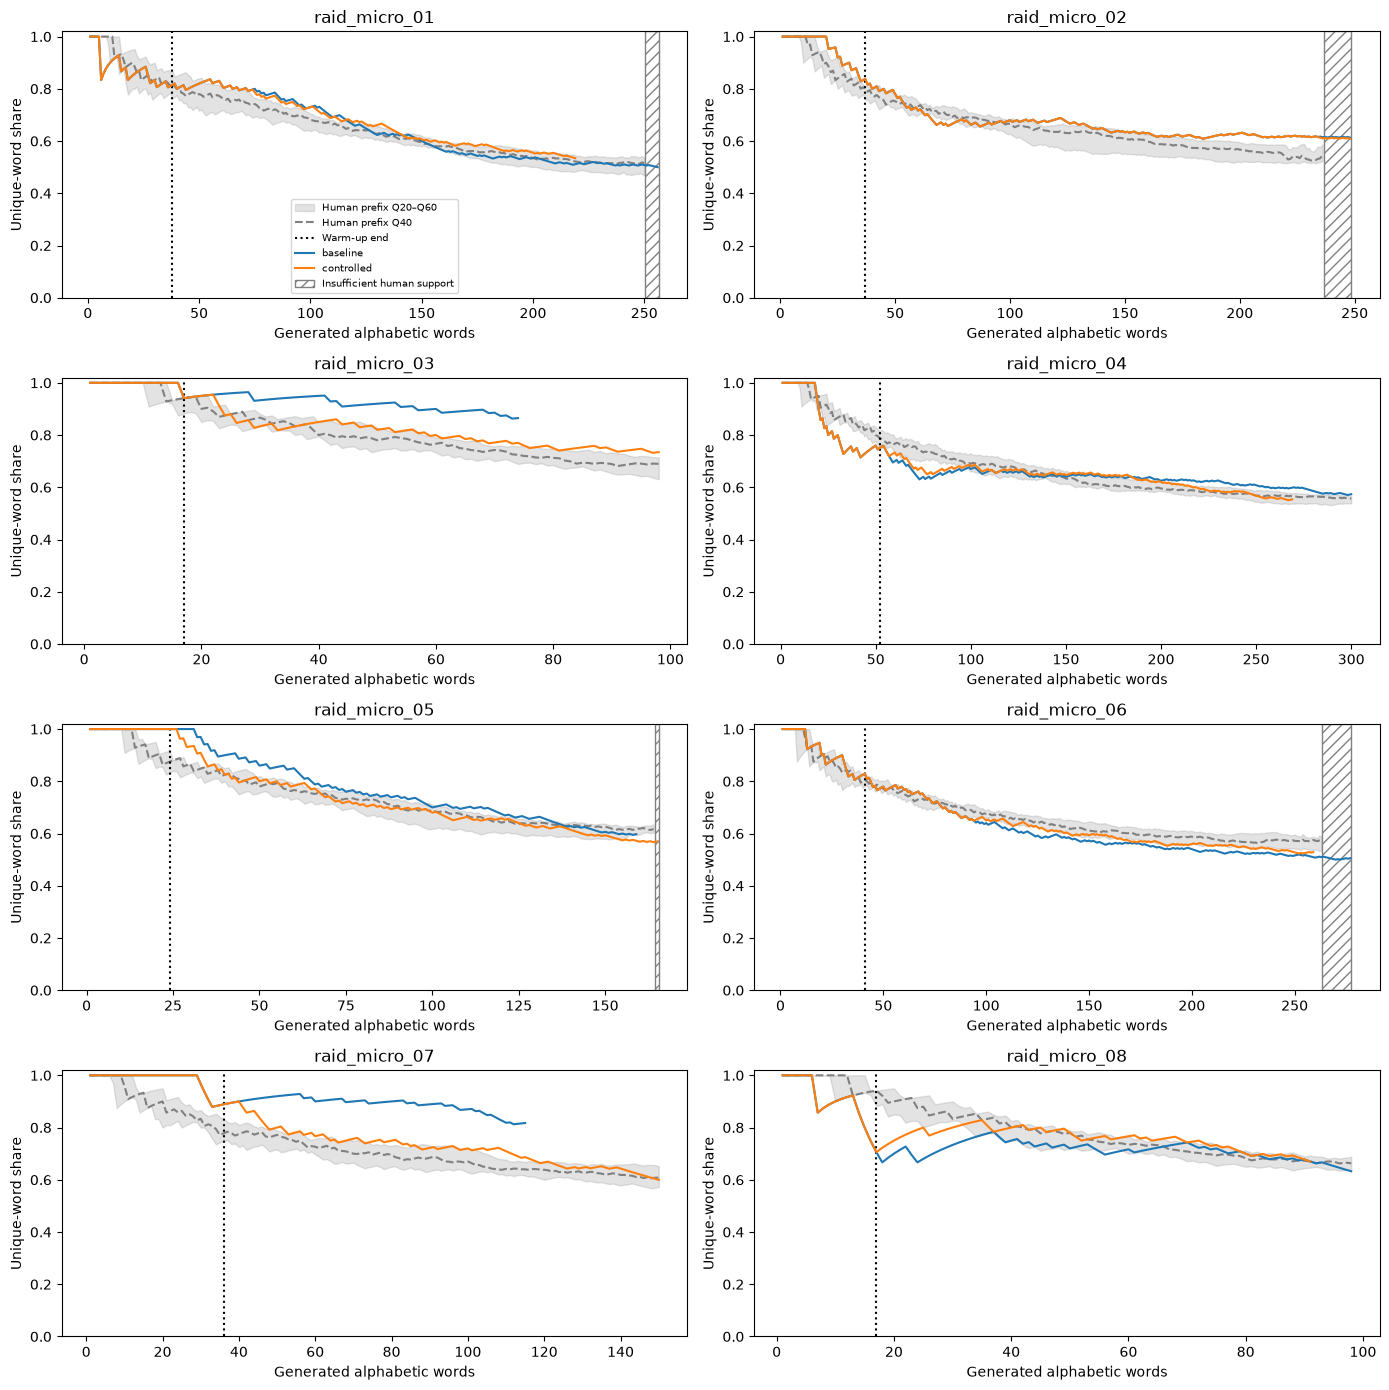

,active_words,searches,replacements,theta_min,theta_median,theta_max
mode_before,,,,,,
decrease,592,358,63,0.005003,0.045275,0.097941
increase,309,156,12,0.005001,0.047766,0.097958


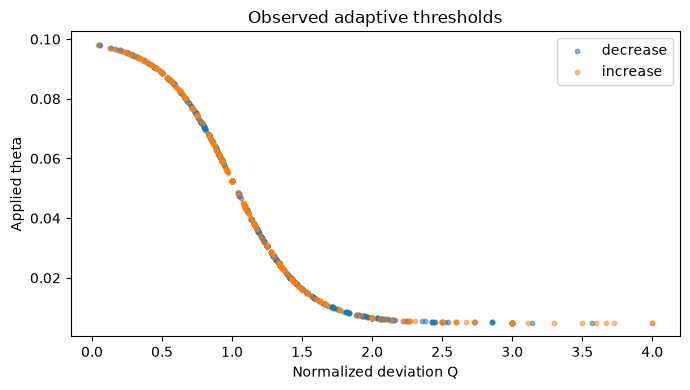

Band metrics are descriptive for supported post-warm-up positions; compare coverage and lengths as well as scores.


In [7]:
rows=[]; reviews=[]; states={}; trajectory_rows=[]
for c in cases:
    texts={}
    for condition in ('baseline','controlled'):
        path=OUT/c['case_id']/condition/'state.json'
        if not path.exists():
            rows.append(dict(case_id=c['case_id'],condition=condition,status='not_started',target_hit=None))
            continue
        payload=json.loads(path.read_text()); assert payload['contract_hash']==CONTRACT_HASH
        s=payload['state']; states[(c['case_id'],condition)]=s
        V,W=counts(s['committed_text']); k=V/W if W else np.nan
        assert W==len(s['words']) and V==len(set(s['words']))
        complete=s['finished'] and s['status']=='completed_eos'
        r=reference_at(c['curve'],W)
        metrics=trajectory_metrics(s['trajectory'],c['warmup_words'])
        rows.append(dict(case_id=c['case_id'],condition=condition,status=s['status'],
            metrics_scope='complete_text' if complete else 'observed_prefix',
            W_ref=c['W_ref'],W_generated=W,length_ratio=W/c['W_ref'],V=V,k=k,
            endpoint_reference_n=r['reference_n'],endpoint_supported=r['supported'],
            target_hit=bool(r['H_h30']<=k<=r['H_a10']) if complete and W and r['supported'] else None,
            search_attempts=s['search_attempts'],replacements=s['replacements'],fallbacks=s['fallbacks'],**metrics))
        texts[condition]=s['committed_text']
        for step in s['trajectory']:
            trajectory_rows.append(dict(case_id=c['case_id'],condition=condition,**step))
    b=states.get((c['case_id'],'baseline')); t=states.get((c['case_id'],'controlled'))
    if b and t:
        n=min(c['warmup_words'],len(b['words']),len(t['words']))
        assert [x['word'] for x in b['trajectory'][:n]]==[x['word'] for x in t['trajectory'][:n]]
        assert all(x['action']=='ordinary' for x in t['trajectory'][:n])
    reviews.append(dict(case_id=c['case_id'],original=c['original'],**texts,
        meaning_preserved='',facts_names_numbers_preserved='',review_notes=''))
summary=pd.DataFrame(rows)
summary.to_csv(OUT/'generation_summary.csv',index=False)
review_path=OUT/'manual_review.csv'; review_frame=pd.DataFrame(reviews)
if review_path.exists():
    previous=pd.read_csv(review_path,keep_default_na=False).set_index('case_id')
    for field in ('meaning_preserved','facts_names_numbers_preserved','review_notes'):
        review_frame[field]=review_frame.case_id.map(previous[field]).fillna('')
review_frame.to_csv(review_path,index=False)
write_json(OUT/'regenerated_texts.json',dict(contract_hash=CONTRACT_HASH,cases=[dict(
    case_id=c['case_id'],original=c['original'],outputs={condition:dict(
    text=states[(c['case_id'],condition)]['committed_text'],status=states[(c['case_id'],condition)]['status'])
    for condition in ('baseline','controlled') if (c['case_id'],condition) in states}) for c in cases]))
display(summary)
fig,axes=plt.subplots(4,2,figsize=(14,14),squeeze=False)
for ax,c in zip(axes.flat,cases):
    lengths=[len(states[(c['case_id'],condition)]['words']) for condition in ('baseline','controlled') if (c['case_id'],condition) in states]
    horizon=max(lengths,default=c['W_ref'])
    ws=np.arange(1,horizon+1)
    ref=[reference_at(c['curve'],int(w)) for w in ws]
    def qvalues(name): return [r.get(name,np.nan) for r in ref]
    ax.fill_between(ws,qvalues('H_h30'),qvalues('H_a10'),color='gray',alpha=.22,label='Human prefix Q20–Q60')
    ax.plot(ws,qvalues('H_h10'),color='gray',ls='--',label='Human prefix Q40')
    ax.axvline(c['warmup_words'],color='black',ls=':',label='Warm-up end')
    for condition,color in [('baseline','tab:blue'),('controlled','tab:orange')]:
        s=states.get((c['case_id'],condition))
        if s and s['trajectory']:
            ax.plot([p['W_after'] for p in s['trajectory']],[p['k_after'] for p in s['trajectory']],
                color=color,label=condition+(' (incomplete)' if not s['finished'] else ''))
    first_unsupported=next((int(w) for w,r in zip(ws,ref) if not r['supported']),None)
    if first_unsupported is not None:
        ax.axvspan(first_unsupported-.5,horizon+.5,facecolor='none',edgecolor='gray',hatch='///',label='Insufficient human support')
    ax.set(title=c['case_id'],xlabel='Generated alphabetic words',ylabel='Unique-word share',ylim=(0,1.02))
axes.flat[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT/'adaptive_prefix_trajectories.png',dpi=180,bbox_inches='tight');plt.show()

# Thresholds actually applied, not a fitted response curve.
trajectory_frame=pd.DataFrame(trajectory_rows)
active=trajectory_frame.loc[(trajectory_frame.condition=='controlled') & trajectory_frame.theta.notna()].copy()
if len(active):
    active['searched']=active.action.isin(['backtracked','fallback_exhausted'])
    active['accepted']=active.action.eq('backtracked')
    display(active.groupby('mode_before').agg(active_words=('action','size'),searches=('searched','sum'),
        replacements=('accepted','sum'),theta_min=('theta','min'),theta_median=('theta','median'),theta_max=('theta','max')))
    fig,ax=plt.subplots(figsize=(7,4))
    for mode,group in active.groupby('mode_before'):
        ax.scatter(group.Q,group.theta,s=10,alpha=.5,label=mode)
    ax.set(xlabel='Normalized deviation Q',ylabel='Applied theta',title='Observed adaptive thresholds');ax.legend()
    fig.tight_layout();fig.savefig(OUT/'adaptive_thresholds.png',dpi=180);plt.show()
    active.to_csv(OUT/'adaptive_active_words.csv',index=False)
print('Band metrics are descriptive for supported post-warm-up positions; compare coverage and lengths as well as scores.')

## Frozen detector scores and feature-wide heatmaps
Run after all texts reach EOS. The original C02e2 extractor is embedded below and verified against all cached original features. No detector outcome changes generation. Green contribution movement means a lower AI score. Tree-path contributions reconstruct scores exactly but are not causal feature effects. Scores are not calibrated authorship probabilities.

In [8]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

condition,original,baseline,controlled,controlled_minus_baseline,controlled_minus_original
case_id,,,,,
raid_micro_01,0.649867,0.687626,0.607102,-0.080524,-0.042765
raid_micro_02,0.651501,0.572330,0.567469,-0.004861,-0.084032
raid_micro_03,0.660483,0.702749,0.571638,-0.131110,-0.088844
raid_micro_04,0.660908,0.673229,0.655904,-0.017325,-0.005004
raid_micro_05,0.590246,0.609352,0.565913,-0.043439,-0.024333
raid_micro_06,0.590607,0.595183,0.556930,-0.038253,-0.033676
raid_micro_07,0.591105,0.613333,0.569922,-0.043411,-0.021183
raid_micro_08,0.593705,0.550241,0.536791,-0.013450,-0.056914


,mean,median
condition,,
baseline,0.625505,0.611343
controlled,0.578959,0.568696
original,0.623553,0.621786


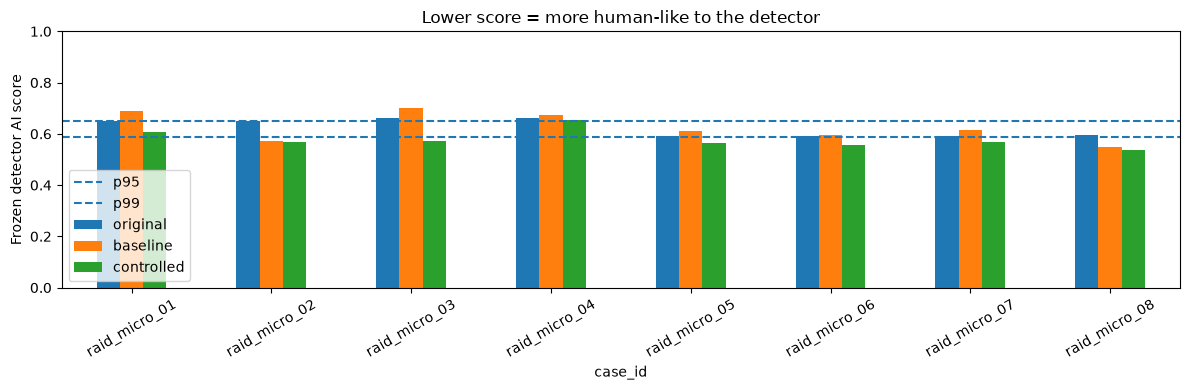

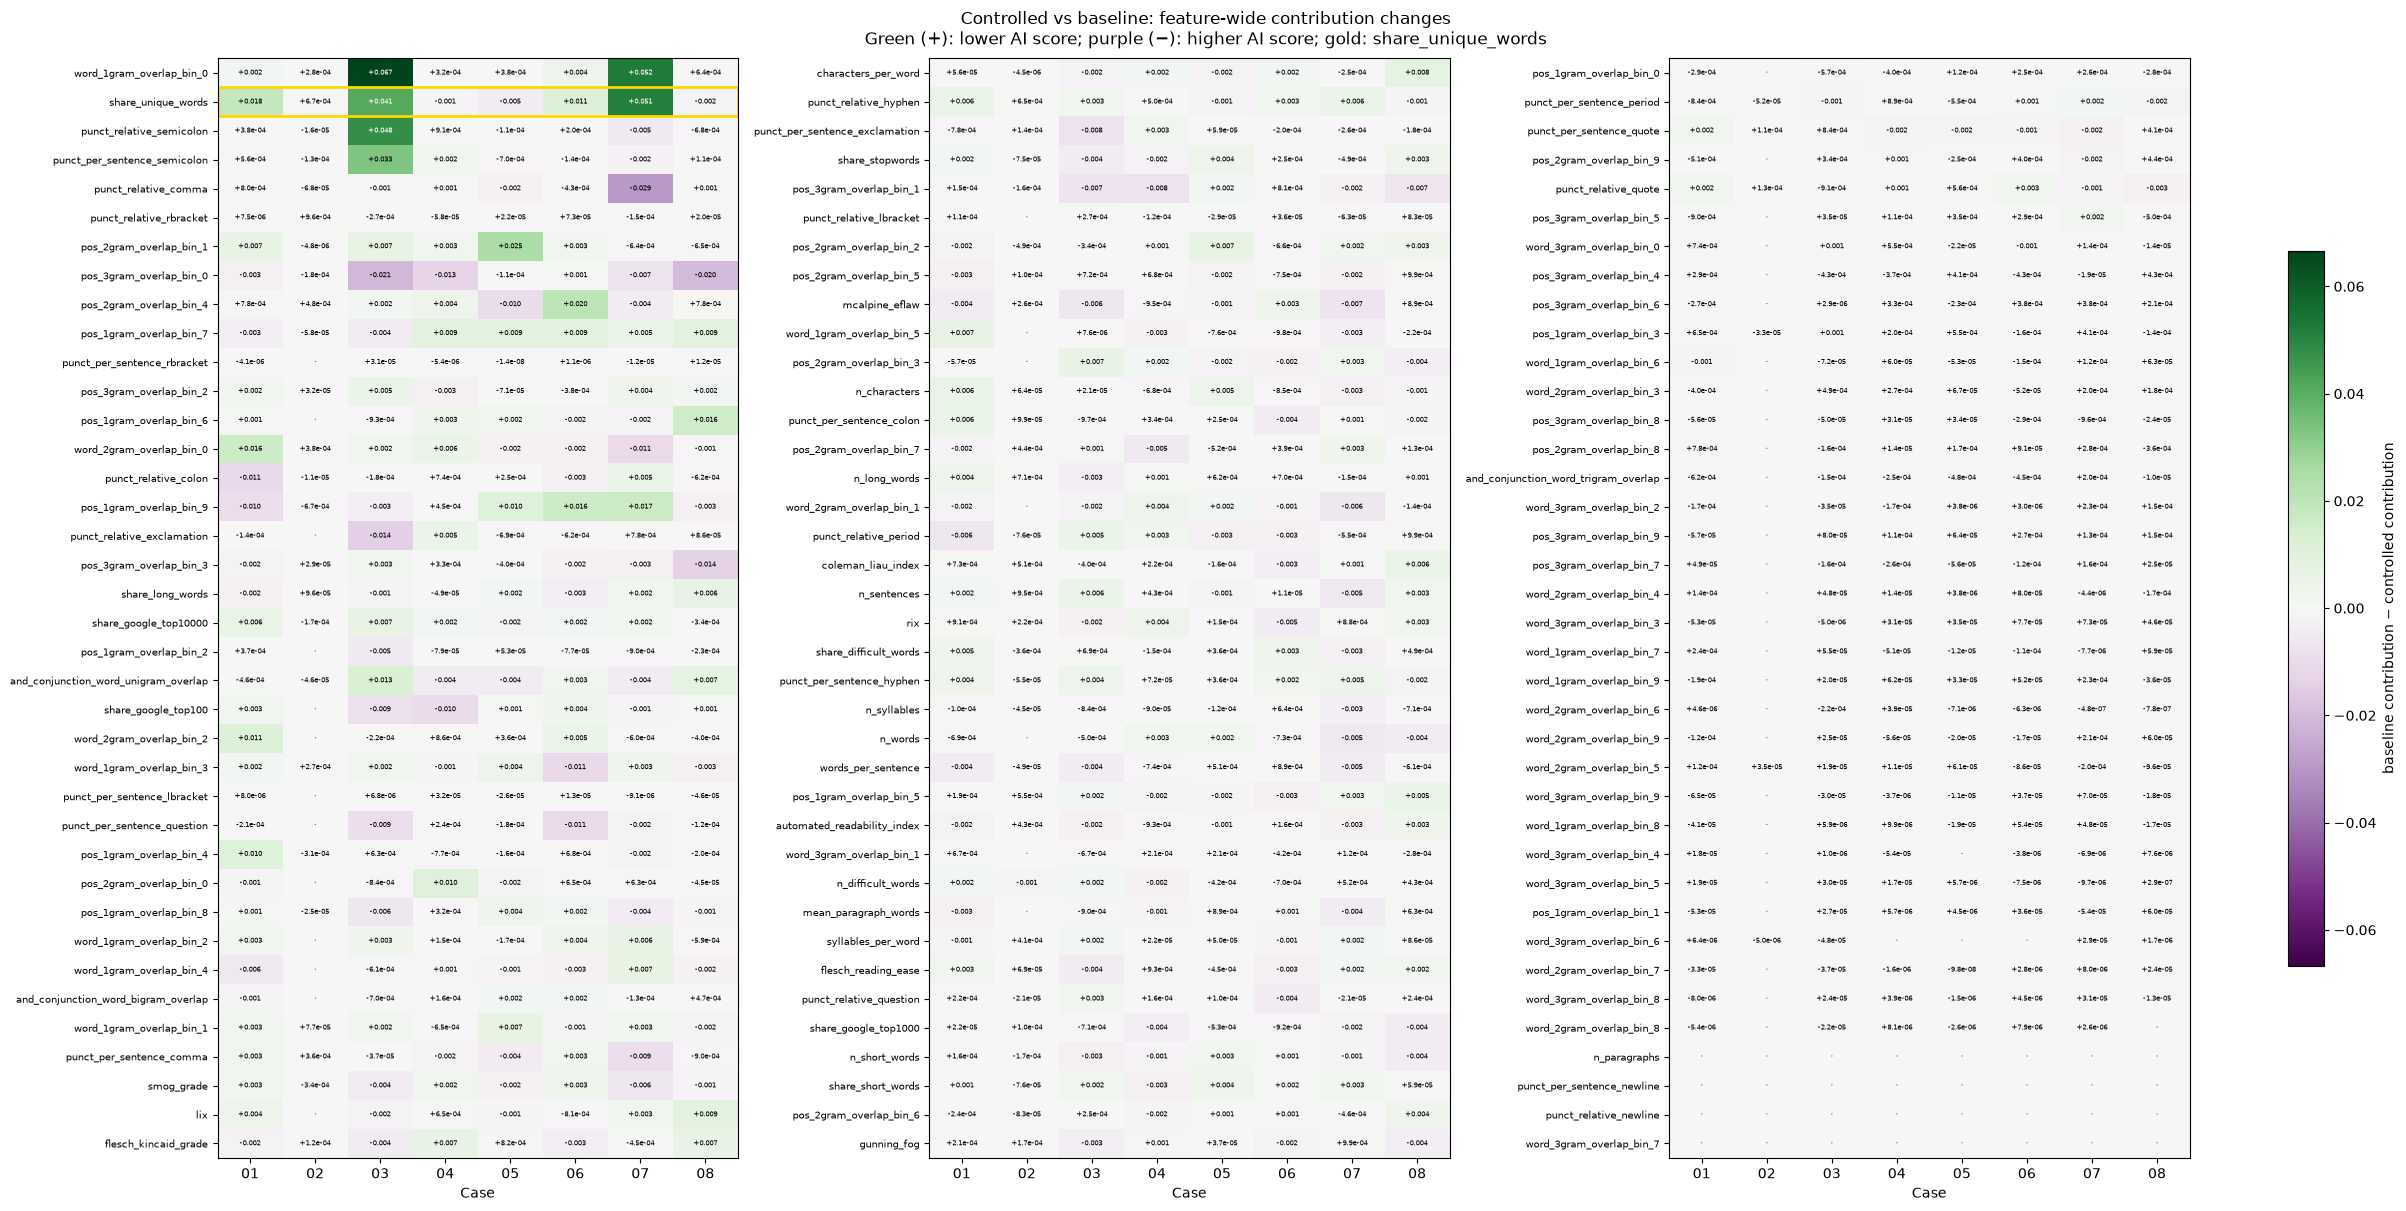

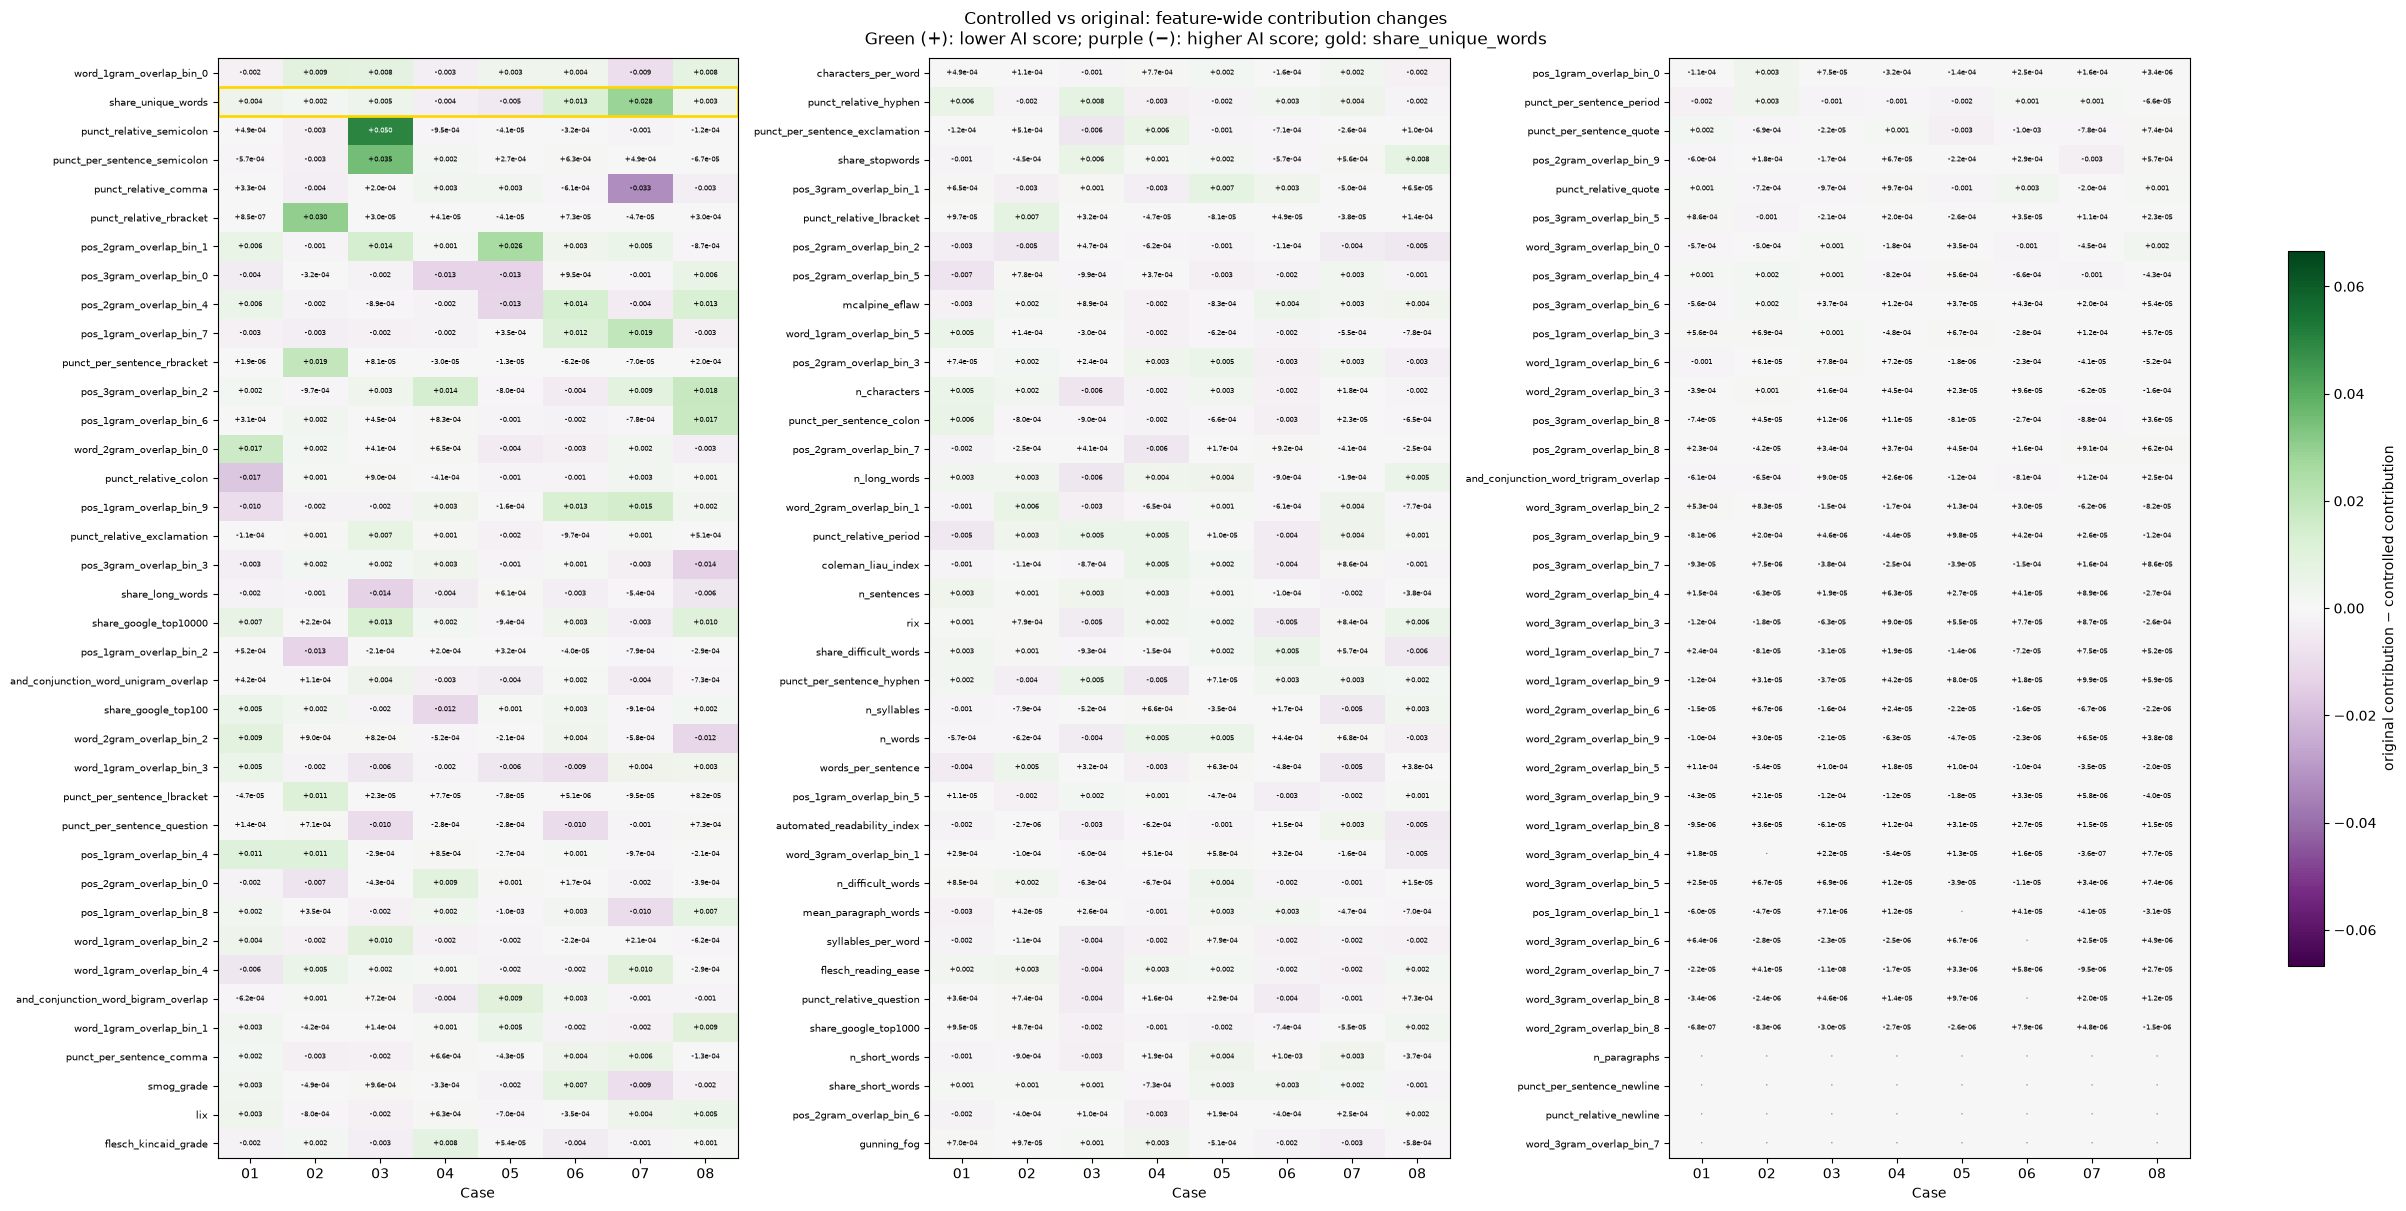

In [9]:
from matplotlib.patches import Rectangle
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f: detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
records=[];vectors=[]
for c in cases:
    original=extract_fz118(c['original'].translate(str.maketrans({'\n':' ','\r':' '})))
    np.testing.assert_allclose(original,feature_map.loc[c['source_id'],FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0)
    for condition in ['original','baseline','controlled']:
        if condition=='original': text=c['original']; vector=original
        else:
            payload=json.loads((OUT/c['case_id']/condition/'state.json').read_text())
            assert payload['contract_hash']==CONTRACT_HASH
            state=payload['state'];assert state['finished'] and state['status']=='completed_eos','Complete generation before scoring.'
            text=state['committed_text'];vector=extract_fz118(text.translate(str.maketrans({'\n':' ','\r':' '})))
        records.append(dict(case_id=c['case_id'],condition=condition,W=counts(text)[1]));vectors.append(vector)
frame=pd.DataFrame(vectors,columns=FEATURE_NAMES)[model_features]
score_table=pd.DataFrame(records);score_table['AI_score']=detector.predict_proba(frame)[:,1]
wide=score_table.pivot(index='case_id',columns='condition',values='AI_score')[['original','baseline','controlled']]
wide['controlled_minus_baseline']=wide.controlled-wide.baseline
wide['controlled_minus_original']=wide.controlled-wide.original
display(wide.round(6));display(score_table.groupby('condition').AI_score.agg(['mean','median']))
score_table.to_csv(OUT/'rewrite_detector_scores.csv',index=False)
wide.to_csv(OUT/'rewrite_detector_score_comparison.csv')
ax=wide[['original','baseline','controlled']].plot.bar(figsize=(12,4),rot=30)
for op in pd.read_csv(PRIOR/'raid_operating_points_p95_p99.csv').itertuples():
    ax.axhline(op.validation_human_threshold,ls='--',label=f'p{round(op.human_specificity_target*100)}')
ax.set(ylabel='Frozen detector AI score',ylim=(0,1),title='Lower score = more human-like to the detector');ax.legend()
ax.figure.tight_layout();ax.figure.savefig(OUT/'rewrite_detector_scores.png',dpi=180);plt.show()

X=frame.to_numpy(np.float32);contrib=np.zeros(X.shape);bias=0.
for est in detector.estimators_:
    t=est.tree_;v=t.value[:,0,:];p=v[:,1]/v.sum(axis=1);bias+=p[0]
    for row in range(len(X)):
        node=0
        while t.feature[node]>=0:
            j=t.feature[node];child=t.children_left[node] if X[row,j]<=t.threshold[node] else t.children_right[node]
            contrib[row,j]+=p[child]-p[node];node=child
contrib/=len(detector.estimators_);bias/=len(detector.estimators_)
np.testing.assert_allclose(bias+contrib.sum(axis=1),score_table.AI_score,atol=1e-9,rtol=0)
cf=pd.DataFrame(contrib,index=pd.MultiIndex.from_frame(score_table[['case_id','condition']]),columns=model_features)
movements={name:(cf.xs(name,level='condition')-cf.xs('controlled',level='condition')).T for name in ['baseline','original']}
importance=pd.concat([m.abs() for m in movements.values()],axis=1).max(axis=1)
order=importance.sort_values(ascending=False).index.tolist();limit=max(float(importance.max()),1e-8)
for name,m in movements.items():
    np.testing.assert_allclose(m.sum(axis=0).reindex(wide.index),wide[name]-wide.controlled,atol=1e-9,rtol=0)
    fig,axes=plt.subplots(1,3,figsize=(24,12),layout='constrained')
    for ax,block in zip(axes,np.array_split(np.array(order),3)):
        data=m.loc[block];im=ax.imshow(data,cmap='PRGn',vmin=-limit,vmax=limit,aspect='auto')
        ax.set_yticks(range(len(block)),block,fontsize=7)
        ax.set_xticks(range(len(data.columns)),[c.replace('raid_micro_','') for c in data.columns]);ax.set_xlabel('Case')
        for row,feature in enumerate(block):
            if feature=='share_unique_words':ax.add_patch(Rectangle((-.5,row-.5),len(data.columns),1,fill=False,edgecolor='gold',lw=2))
            for col,value in enumerate(data.iloc[row]):
                label='·' if abs(value)<1e-9 else f'{value:+.3f}' if abs(value)>=.001 else f'{value:+.1e}'
                ax.text(col,row,label,ha='center',va='center',fontsize=5,color='white' if abs(value)>.6*limit else 'black')
    fig.suptitle(f'Controlled vs {name}: feature-wide contribution changes\nGreen (+): lower AI score; purple (−): higher AI score; gold: share_unique_words')
    fig.colorbar(im,ax=list(axes),shrink=.65,label=f'{name} contribution − controlled contribution')
    fig.savefig(OUT/f'heatmap_controlled_vs_{name}.png',dpi=200,bbox_inches='tight');plt.show()
    m.to_csv(OUT/f'contribution_movement_vs_{name}.csv')

In [10]:
from IPython.display import display, Markdown

REVIEW_CASE_IDS = ["raid_micro_03", "raid_micro_06", "raid_micro_07"]

review_corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
review_texts = review_corpus.set_index("source_id")["text"].to_dict()
cases_by_id = {c["case_id"]: c for c in cases}

for case_id in REVIEW_CASE_IDS:
    case = cases_by_id[case_id]

    # Select from the frozen human references without looking at detector scores.
    candidates = [r for r in references if r["case_id"] == case_id]
    if not candidates:
        raise ValueError(f"No frozen human references for {case_id}.")

    human = min(
        candidates,
        key=lambda r: (
            abs(math.log(max(r["W"], 1) / case["W_ref"])),
            str(r["source_id"]),
        ),
    )
    human_text = str(review_texts[human["source_id"]])

    state_path = OUT / case_id / "controlled" / "state.json"
    payload = json.loads(state_path.read_text())
    assert payload["contract_hash"] == CONTRACT_HASH

    state = payload["state"]
    assert state["finished"] and state["status"] == "completed_eos", (
        f"{case_id}: controlled generation is incomplete."
    )
    controlled_text = state["committed_text"]

    display(Markdown(f"## {case_id} — {case['domain']}"))

    if case["reference_fallback"]:
        print("Human reference uses the pooled-domain fallback.")

    for label, text in [
        ("HUMAN REFERENCE — independent passage",
         human_text),
        ("ORIGINAL AI — source passage",
         case["original"]),
        ("CONTROLLED AI — rewritten source passage",
         controlled_text),
    ]:
        V, W = counts(text)
        ratio = f"{V / W:.4f}" if W else "undefined"
        display(Markdown(
            f"### {label}\n\n"
            f"Alphabetic words: **{W}** · Unique-word share: **{ratio}**"
        ))
        print(text)  # Full text, preserving line breaks; no dataframe truncation.
        print()

    display(Markdown(
        "**Review:** Did the controlled rewrite preserve the source's claims, "
        "details, names, tone, and coherence? Look especially for omissions, "
        "changed meanings, and unnatural repetition."
    ))

## raid_micro_03 — reddit

### HUMAN REFERENCE — independent passage

Alphabetic words: **121** · Unique-word share: **0.6942**

Obviously Attila predates our modern understanding of "conservative" or "right wing" by thousands of years, but I'm still quite confused. As you may recall, last year, Kelly Loeffler ran a campaign ad in which she claimed to be "more conservative then Attila the Hun." This confused me, as I'd never heard anything about Attila being particularly conservative; I also just read a Donald Trump quote from the 2000 election cycle, in which he said, "I'm on the conservative side, but Buchanan is Attila the Hun." Hearing two comparisons of conservatives to Attila the Hun has just left me confused, so I came here to ask anyone who can answer: was Attila the Hun especially conservative? Enough so to warrant these hyperbolic comparisons?



### ORIGINAL AI — source passage

Alphabetic words: **107** · Unique-word share: **0.7383**

I'm sure many preppers out there have heard about lifeboats, but how much is enough? It's important to have a plan in place and supplies stockpiled for when SHTF, but it can be overwhelming to figure out what you need and how much of it. In my experience, I've found that having at least three months' worth of food and water, as well as essentials like medicine and hygiene products, is a good starting point. But don't stop there! Keep adding to your stash and learning new skills so that you're always prepared for whatever comes your way. Remember, knowledge is power - stay informed and stay safe!



...

### ORIGINAL AI — source passage

Alphabetic words: **238** · Unique-word share: **0.7227**

Azaleas unfold blushing gowns, beneath the pecan trees,
The magnolias blossom, carried on the soft, warm breeze
Rivers carry golden pollen, the essence of the pines,
Sweet aroma fills the air from confederate jasmine vines.

Redbud trees in bloom against a clear Carolina blue,
Spanish moss gently hangs, creating an ethereal view.
Cardinals flutter, gifting spots of fiery, passionate red,
Tender footsteps of a deer, where the camellia petals spread.

Wisteria weaves a blanket, lilac clusters hanging fair,
In the field of buttercups, sunlight creates an amber glare.
Mockingbirds reciting songs, in the southern live oak’s shade,
A quartet of melody and colour, a symphony, nature-made.

The song of the cicadas echoes, as day gives into evening's hush,
Fireflies begin their dance, in the mellow dusk-light rush.
The promise of humid nights, under a moon laced with silver touch,
Such is the bewitching charm, of a southern springtime’s clutch. 

Its warmth seeps into your bones, like sweet tea

### CONTROLLED AI — rewritten source passage

Alphabetic words: **150** · Unique-word share: **0.6000**

Azaleas unfurl in blush, beneath pecan trees,
Magnolias bloom, carried on a gentle breeze.
Rivers carry pollen, pine essence fills the air,
Confederate jasmine vines, sweet fragrance spreads.

Redbud trees in bloom, a clear Carolina blue,
Spanish moss hangs gently, a mew’th air.
Cardinals flutter, a firecrack’r in the air,
Deer’s tender steps, confederate jasmine’s spread.

Wisteria weaves a blanket, lilac hangs fair,
Buttercups in a field, a golden amber light.
Mockingbirds sing, in a southern live oak’s shade,
A quartet of melody, a southern spring.

The song of the cicadas echoes, as the day fades,
Fireflies dance, in the mellow dusk-light rush.
Humid nights, a moon laced with a silv’ry light,
A southern spring, a spell, a southern spring.

The south unfurls in a gentle spring, a silent invitation,
A bygone era, a hoop skirt’s sway.
Beneath the lazy sun, a southern spring,
A spell, a southern spring, a southern spring.



**Review:** Did the controlled rewrite preserve the source's claims, details, names, tone, and coherence? Look especially for omissions, changed meanings, and unnatural repetition.